# Does nonlinear model form improve UCL risk prediction?

Compare linear logistic regression, additive cubic spline logistic models and constrained histogram boosting. Stumps provide an additive tree comparison. Reuse the refined UCL endpoint, frozen representations and 30-day appearance landmarks. No previous stage is redone.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
while not (ROOT/'src/injury_analysis').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_nonlinear_common import OUT, CACHE, CFG, read_table
pd.set_option('display.max_columns',20)
protocol=json.loads((OUT/'frozen_protocol.json').read_text())
def show(name,n=25):display(read_table(name).head(n))
def plot(name):display(Image(filename=str(OUT/'figures'/(name+'.png')),width=1150))


In [2]:
from src.injury_analysis.ucl_nonlinear_models import run_models
run_models()  # verified checkpoint reuse
show('cohort_counts')
display({k:protocol[k] for k in ['warning_leaders','ranking_leaders','frozen_at_utc']})

,partition,rows,pitchers,positive_rows,represented_events
0,train,87332,1308,338,59
1,validation,28875,802,138,25
2,test,29349,802,142,28


{'warning_leaders': {'Linear': 'Linear|Departure',
  'Spline': 'Departure__Spline__0p1',
  'Boosting': 'Departure__Boosting__8'},
 'ranking_leaders': {'Linear': 'Linear|Stable 62',
  'Spline': 'Profile__Spline__0p1',
  'Boosting': 'Profile__Boosting__4'},
 'frozen_at_utc': '2026-10-15T03:58:54.653596+00:00'}

## Fixed design and modest search

Training: 2015–2021; validation: 2022–2023; previously examined exploratory transfer: 2024–2025. Preserve the 60-day embargo, first-event competing-injury outcomes, observed follow-up, source NULLs and post-completed-outing cutoff. Fit 35 nonlinear candidates across seven existing representations: two spline penalties and three tree sizes. Knots, imputation, clipping and scaling are training-only. No class rebalancing, synthetic injuries or automatic random early-stopping split.

The primary selection uses validation ≥7-day warning recall at 5% budget; an AP leader is frozen separately. Choices and thresholds were saved before transfer predictions. The two leaders answer different questions.

In [3]:
show('development_search',n=20)
show('representation_comparison',n=25)

,partition,model_id,representation,algorithm,setting,complexity,raw_features,rows,pitchers,positive_rows,...,roc_auc,brier_score,mean_predicted_risk,calibration_bias,pr_lift,injury_event_recall,alerted_events,qualifying_events,median_warning_lead_days,non_actionable_alert_fraction
0,train,Linear|Background,Background,Linear,1.0,0,7,87332,1308,338,...,0.647583,0.003851,0.003870,-8.054153e-09,1.877663,0.061224,6,98,26.5,0.992671
1,validation,Linear|Background,Background,Linear,1.0,0,7,28875,802,138,...,0.652762,0.004751,0.004159,-6.199188e-04,1.592442,0.058824,2,34,27.5,0.995149
2,train,Linear|Profile,Profile,Linear,1.0,0,13,87332,1308,338,...,0.669506,0.003849,0.003870,2.956122e-08,2.459317,0.061224,6,98,26.0,0.993129
3,validation,Linear|Profile,Profile,Linear,1.0,0,13,28875,802,138,...,0.582491,0.004758,0.003631,-1.147791e-03,1.279588,0.000000,0,34,NaN,1.000000
4,train,Linear|Departure,Departure,Linear,1.0,0,8,87332,1308,338,...,0.628508,0.003851,0.003870,5.504061e-09,2.075324,0.193878,19,98,17.0,0.993816
5,validation,Linear|Departure,Departure,Linear,1.0,0,8,28875,802,138,...,0.557629,0.004755,0.003946,-8.335351e-04,1.521611,0.205882,7,34,12.0,0.993763
6,train,Linear|Profile + departure,Profile + departure,Linear,1.0,0,21,87332,1308,338,...,0.712975,0.003844,0.003870,-4.300583e-08,2.762181,0.163265,16,98,23.0,0.992213
7,validation,Linear|Profile + departure,Profile + departure,Linear,1.0,0,21,28875,802,138,...,0.591534,0.004757,0.003602,-1.177677e-03,1.542537,0.088235,3,34,12.0,0.995149
8,train,Linear|Profile + departure + trajectory,Profile + departure + trajectory,Linear,1.0,0,33,87332,1308,338,...,0.734230,0.003842,0.003870,4.578647e-08,3.065690,0.183673,18,98,20.5,0.989693
9,validation,Linear|Profile + departure + trajectory,Profile + departure + trajectory,Linear,1.0,0,33,28875,802,138,...,0.603309,0.004758,0.003609,-1.169757e-03,1.609540,0.088235,3,34,12.0,0.994456


,partition,model_id,representation,algorithm,setting,complexity,raw_features,rows,pitchers,positive_rows,...,roc_auc,brier_score,mean_predicted_risk,calibration_bias,pr_lift,injury_event_recall,alerted_events,qualifying_events,median_warning_lead_days,non_actionable_alert_fraction
0,train,Linear|Background,Background,Linear,1.0,0,7,87332,1308,338,...,0.647583,0.003851,0.003870,-8.054153e-09,1.877663,0.061224,6,98,26.5,0.992671
1,validation,Linear|Background,Background,Linear,1.0,0,7,28875,802,138,...,0.652762,0.004751,0.004159,-6.199188e-04,1.592442,0.058824,2,34,27.5,0.995149
2,train,Linear|Profile,Profile,Linear,1.0,0,13,87332,1308,338,...,0.669506,0.003849,0.003870,2.956122e-08,2.459317,0.061224,6,98,26.0,0.993129
3,validation,Linear|Profile,Profile,Linear,1.0,0,13,28875,802,138,...,0.582491,0.004758,0.003631,-1.147791e-03,1.279588,0.000000,0,34,NaN,1.000000
4,train,Linear|Departure,Departure,Linear,1.0,0,8,87332,1308,338,...,0.628508,0.003851,0.003870,5.504061e-09,2.075324,0.193878,19,98,17.0,0.993816
5,validation,Linear|Departure,Departure,Linear,1.0,0,8,28875,802,138,...,0.557629,0.004755,0.003946,-8.335351e-04,1.521611,0.205882,7,34,12.0,0.993763
6,train,Linear|Profile + departure,Profile + departure,Linear,1.0,0,21,87332,1308,338,...,0.712975,0.003844,0.003870,-4.300583e-08,2.762181,0.163265,16,98,23.0,0.992213
7,validation,Linear|Profile + departure,Profile + departure,Linear,1.0,0,21,28875,802,138,...,0.591534,0.004757,0.003602,-1.177677e-03,1.542537,0.088235,3,34,12.0,0.995149
8,train,Linear|Profile + departure + trajectory,Profile + departure + trajectory,Linear,1.0,0,33,87332,1308,338,...,0.734230,0.003842,0.003870,4.578647e-08,3.065690,0.183673,18,98,20.5,0.989693
9,validation,Linear|Profile + departure + trajectory,Profile + departure + trajectory,Linear,1.0,0,33,28875,802,138,...,0.603309,0.004758,0.003609,-1.169757e-03,1.609540,0.088235,3,34,12.0,0.994456


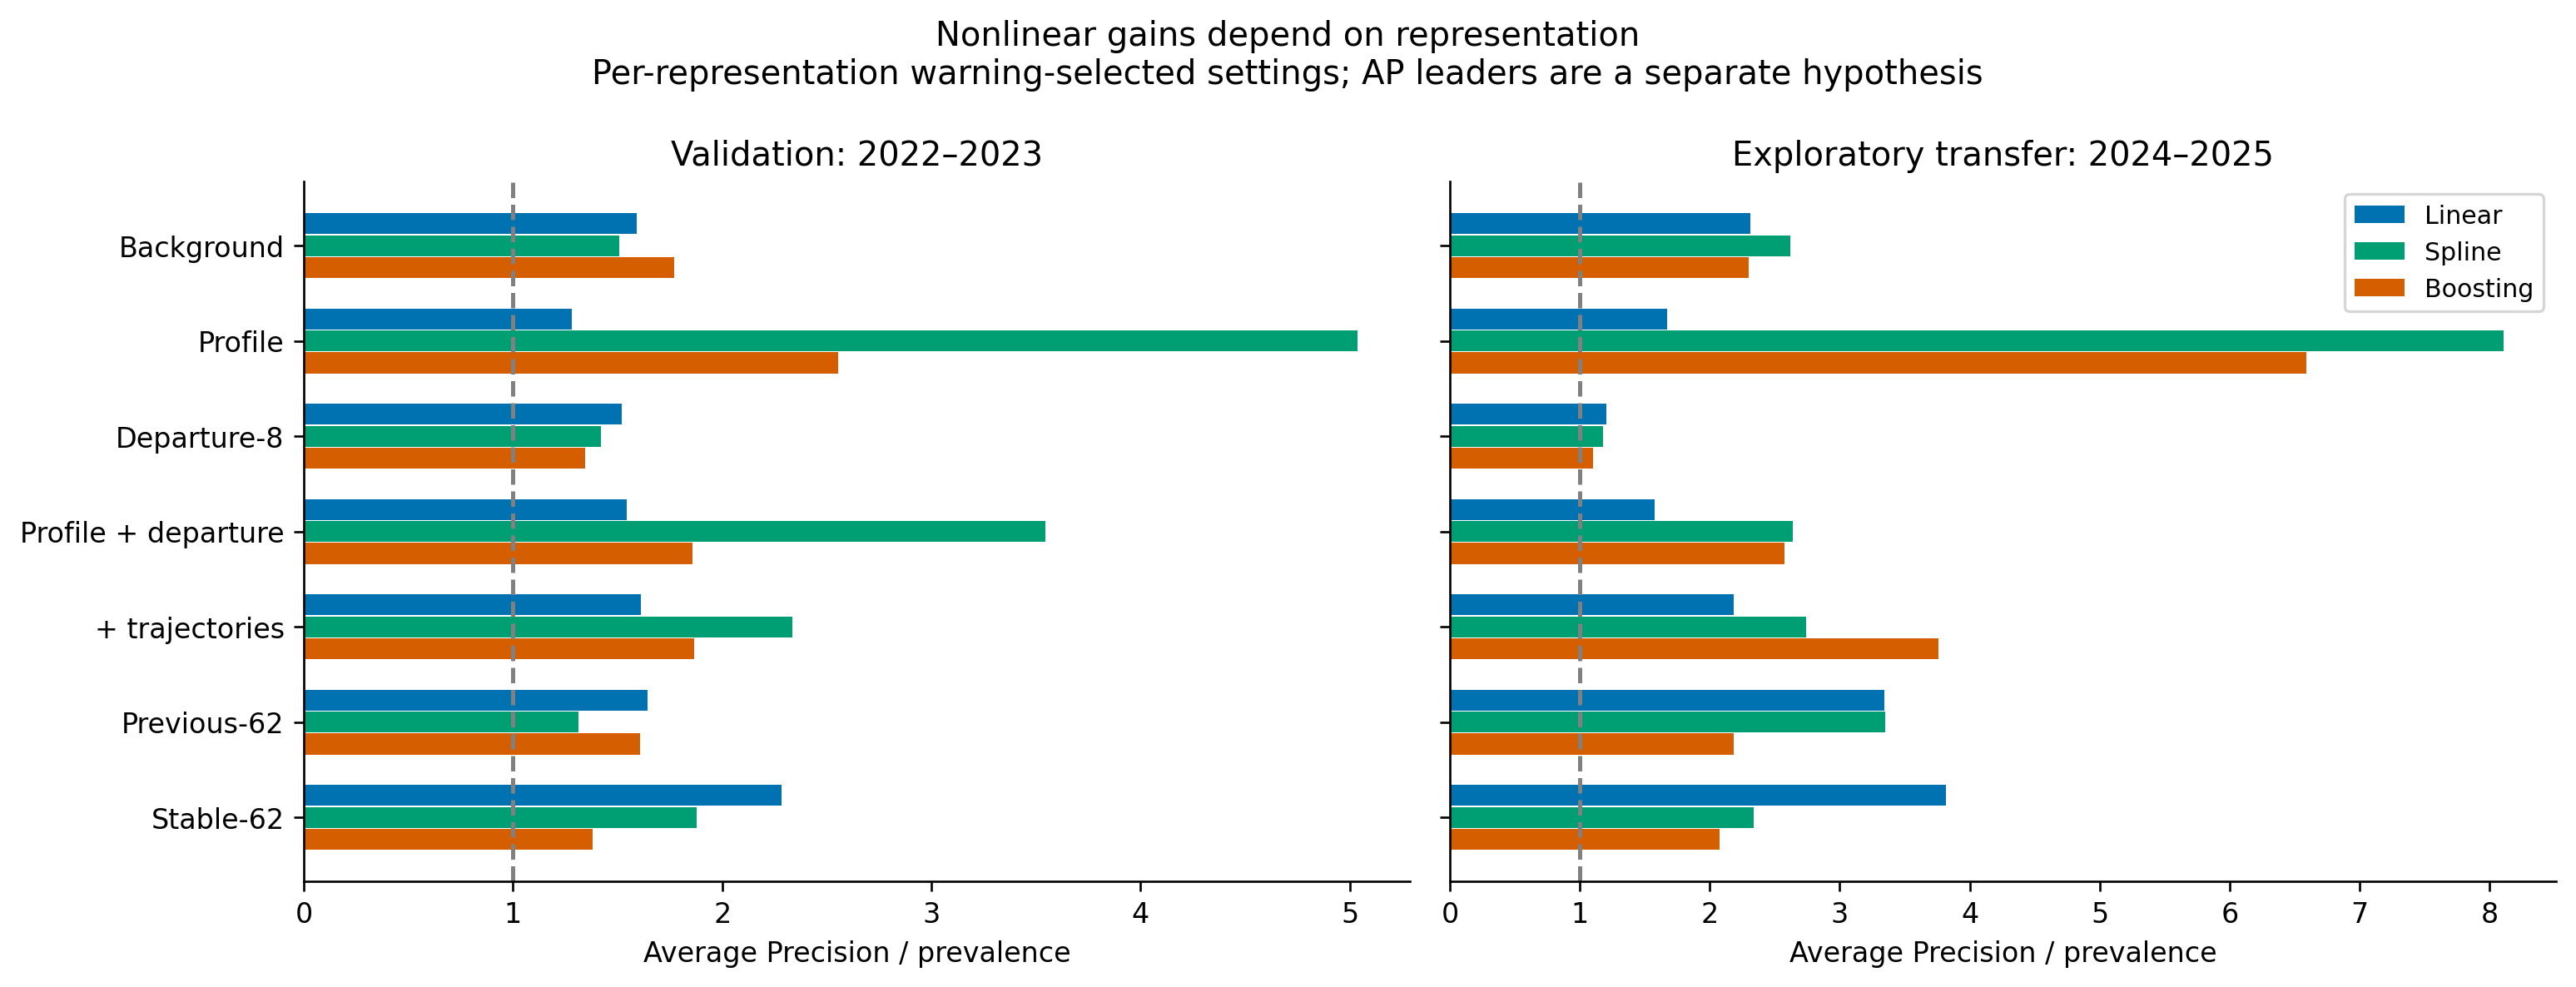

,partition,model_id,representation,algorithm,setting,complexity,raw_features,rows,pitchers,positive_rows,...,roc_auc,brier_score,mean_predicted_risk,calibration_bias,pr_lift,injury_event_recall,alerted_events,qualifying_events,median_warning_lead_days,non_actionable_alert_fraction
0,validation,Linear|Departure,Departure,Linear,1.0,0,8,28875,802,138,...,0.557629,0.004755,0.003946,-0.000834,1.521611,0.205882,7,34,12.0,0.993763
1,validation,Linear|Stable 62,Stable 62,Linear,1.0,0,62,28875,802,138,...,0.661070,0.004772,0.003770,-0.001009,2.284895,0.088235,3,34,15.0,0.993070
2,validation,Profile__Spline__0p1,Profile,Spline,0.1,0,13,28875,802,138,...,0.546154,0.004743,0.003563,-0.001216,5.159748,0.117647,4,34,20.0,0.992377
3,validation,Profile__Boosting__4,Profile,Boosting,4.0,1,13,28875,802,138,...,0.541735,0.004754,0.003330,-0.001449,6.157630,0.088235,3,34,28.0,0.990991
4,validation,Departure__Spline__0p1,Departure,Spline,0.1,0,8,28875,802,138,...,0.566019,0.004758,0.003956,-0.000824,1.420070,0.205882,7,34,12.0,0.993763
5,validation,Departure__Boosting__8,Departure,Boosting,8.0,2,8,28875,802,138,...,0.547116,0.004759,0.003899,-0.000880,1.345783,0.235294,8,34,26.5,0.992377
6,test,Departure__Boosting__8,Departure,Boosting,8.0,2,8,29349,802,142,...,0.523373,0.004822,0.003825,-0.001013,1.101707,0.069767,3,43,17.0,0.997955
7,test,Linear|Departure,Departure,Linear,1.0,0,8,29349,802,142,...,0.564232,0.004817,0.003879,-0.000960,1.206568,0.046512,2,43,14.0,0.997955
8,test,Departure__Spline__0p1,Departure,Spline,0.1,0,8,29349,802,142,...,0.540011,0.004820,0.003871,-0.000967,1.180272,0.069767,3,43,11.0,0.997955
9,test,Linear|Stable 62,Stable 62,Linear,1.0,0,62,29349,802,142,...,0.636216,0.004800,0.003126,-0.001713,3.815035,0.209302,9,43,15.0,0.987730


In [4]:
plot('01_ranking_by_representation')
show('leader_comparison',n=20)

**Result:** Nonlinear departure models do not improve AP. Profile splines and some profile trees can produce large validation AP, while nonlinear broader representations do not uniformly outperform linear benchmarks. The profile spline’s AP gain must be examined for event concentration before it can be considered a reproducible finding.

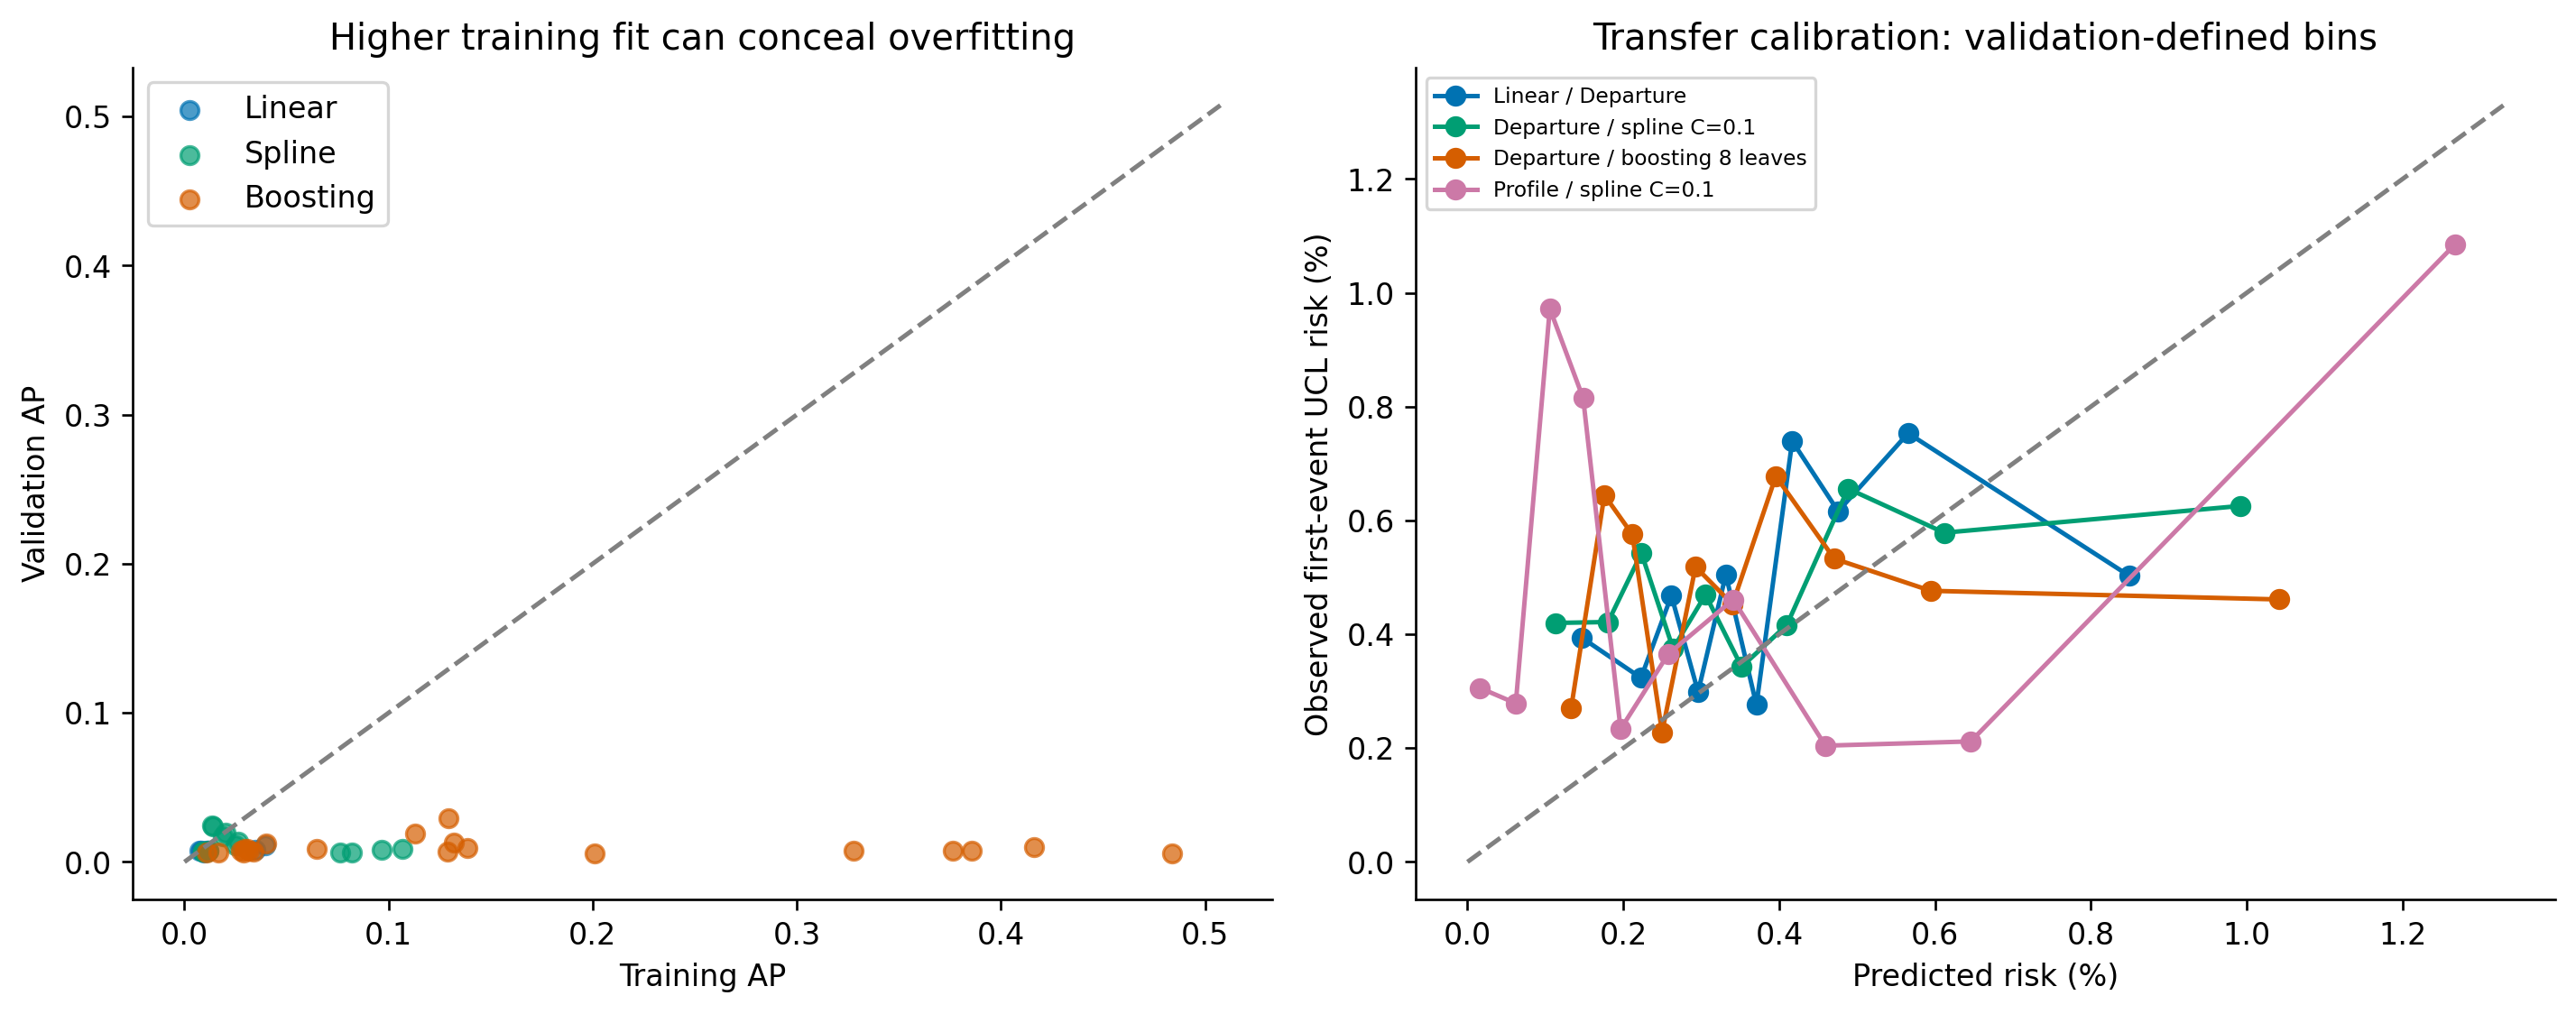

,model_id,train,validation,training_minus_validation_ap
0,Background__Boosting__2,0.031719,0.007695,0.024024
1,Background__Boosting__4,0.064870,0.008453,0.056417
2,Background__Boosting__8,0.138516,0.009101,0.129415
3,Background__Spline__0p1,0.011568,0.007209,0.004359
4,Background__Spline__1p0,0.011458,0.006982,0.004476
5,Departure__Boosting__2,0.010840,0.006539,0.004301
6,Departure__Boosting__4,0.016688,0.006494,0.010194
7,Departure__Boosting__8,0.029136,0.006432,0.022705
8,Departure__Spline__0p1,0.009030,0.006787,0.002243
9,Departure__Spline__1p0,0.009145,0.006773,0.002372


In [5]:
plot('03_overfitting_and_calibration')
show('training_validation_gap',n=20)

**Overfitting:** The profile-tree AP leader has training AP 0.1295, validation AP 0.0294 and transfer AP 0.00646. A strong training fit does not establish a generalizable nonlinear risk relationship. The transfer period remains exploratory; it did not choose these models.

In [6]:
show('additivity_comparison',n=25)

,partition,model_id,representation,algorithm,setting,complexity,raw_features,rows,pitchers,positive_rows,...,brier_score,mean_predicted_risk,calibration_bias,pr_lift,injury_event_recall,alerted_events,qualifying_events,median_warning_lead_days,non_actionable_alert_fraction,model_form
0,validation,Linear|Background,Background,Linear,1.0,0,7,28875,802,138,...,0.004751,0.004159,-0.000620,1.592442,0.058824,2,34,27.5,0.995149,linear additive
1,validation,Linear|Profile,Profile,Linear,1.0,0,13,28875,802,138,...,0.004758,0.003631,-0.001148,1.279588,0.000000,0,34,NaN,1.000000,linear additive
2,validation,Linear|Departure,Departure,Linear,1.0,0,8,28875,802,138,...,0.004755,0.003946,-0.000834,1.521611,0.205882,7,34,12.0,0.993763,linear additive
3,validation,Linear|Profile + departure,Profile + departure,Linear,1.0,0,21,28875,802,138,...,0.004757,0.003602,-0.001178,1.542537,0.088235,3,34,12.0,0.995149,linear additive
4,validation,Linear|Profile + departure + trajectory,Profile + departure + trajectory,Linear,1.0,0,33,28875,802,138,...,0.004758,0.003609,-0.001170,1.609540,0.088235,3,34,12.0,0.994456,linear additive
5,validation,Linear|Previous 62,Previous 62,Linear,1.0,0,62,28875,802,138,...,0.004787,0.003810,-0.000970,1.642216,0.088235,3,34,23.0,0.995149,linear additive
6,validation,Linear|Stable 62,Stable 62,Linear,1.0,0,62,28875,802,138,...,0.004772,0.003770,-0.001009,2.284895,0.088235,3,34,15.0,0.993070,linear additive
7,validation,Background__Spline__0p1,Background,Spline,0.1,0,7,28875,802,138,...,0.004757,0.003867,-0.000912,1.508341,0.058824,2,34,20.5,0.992377,nonlinear additive spline
8,validation,Background__Spline__1p0,Background,Spline,1.0,1,7,28875,802,138,...,0.004760,0.003840,-0.000939,1.460878,0.058824,2,34,20.5,0.992377,nonlinear additive spline
9,validation,Background__Boosting__2,Background,Boosting,2.0,0,7,28875,802,138,...,0.004754,0.004010,-0.000769,1.610162,0.058824,2,34,20.5,0.995149,nonlinear additive boosted stumps
